# Two-Layer Axisymmetric Power-Law Flow: Wire Coating
### Concentric layers in an annulus with a moving wire (combined drag and pressure flow)

This notebook carries the moving-wall slit notebook over to **axisymmetric annular flow**. A wire of radius $R_w$ is pulled along the axis at speed $V_w$ through a die land of radius $R_d$. Two concentric power-law melts fill the annulus: an inner layer against the wire (for example insulation or a primer) and an outer layer against the die (for example a jacket). The solver handles 1 to 5 layers, but the tutorial and examples focus on two.

**You specify:** the wire radius and speed, the die radius, the power-law parameters $(K_i, n_i)$ of each layer, and either the flow rate of each layer or the **final coating thickness** you want on the wire.
**The notebook returns:** the pressure gradient in the die land, the interface radius and velocity, the wall shear stresses, the drag force on the wire, and plots of the cross-section and of the velocity, shear-rate and viscosity profiles.

**Contents**
1. Tutorial: annular momentum balance, the zero-stress radius, how the layer integrals are computed, wire-coating mass balance
2. Solver code
3. Verification (Newtonian annular drag flow, Newtonian Couette–Poiseuille, power-law pure drag, independent quadrature)
4. Worked examples: a two-layer insulated wire, a line-speed sweep, a coating-thickness sweep
5. **Calculation cell: enter your own case**

## 1. Tutorial

### 1.1 Geometry and assumptions

Cylindrical coordinates $(r, \theta, z)$ with the wire on the axis. The annulus runs from $R_w \le r \le R_d$. Layers are numbered $i = 1\dots N$ from the wire outward, with interface radii $R_w = r_0 < r_1 < \dots < r_N = R_d$ (for two layers there is a single interface $r_1$).

Assumptions:
* Steady, isothermal, incompressible, laminar creeping flow in the **die land**, the straight annular section just before the exit.
* **Fully developed** axial flow $u = u_z(r)$, with cylindrical, concentric interfaces. The wire is centred, and the converging entry section, extrudate swell and draw-down after the die are not modelled.
* No slip on the wire ($u = V_w$) and the die wall ($u = V_d$, normally 0). Velocity and shear stress are continuous at the interfaces.
* Power-law layers: $\tau_{rz} = K_i|\dot\gamma|^{n_i-1}\dot\gamma$, with $\dot\gamma = du/dr$.

Viscous heating can be significant at high line speeds. The isothermal model ignores it, so treat high-speed results as first estimates.

### 1.2 Momentum balance: the stress is no longer linear

The axial momentum balance in a cylindrical shell is
$$\frac{1}{r}\frac{d}{dr}\left(r\,\tau_{rz}\right) = \frac{dp}{dz} \equiv -G
\quad\Longrightarrow\quad
\boxed{\;\tau_{rz}(r) = -\frac{G\,r}{2} + \frac{C}{r}\;}$$
Because $r\tau_{rz}$ is continuous across every interface and $G$ is the same in every layer, **one pair of constants $(G, C)$ describes the stress in all layers**. This is the annular counterpart of the single stress line in the slit. Compared with the slit:

* The stress is a straight line plus a $1/r$ term. The $1/r$ term is the curvature effect, and it disappears when $(R_d - R_w)/R_w \to 0$.
* When $G$ and $C$ have the same sign, the stress vanishes at the **zero-stress radius**
  $$r^* = \sqrt{2C/G}, \qquad \tau_{rz}(r) = -\frac{G}{2}\,\frac{(r - r^*)(r + r^*)}{r}.$$
  This radius can lie inside the annulus (a velocity extremum) or outside it. With $G = 0$ (pure drag) it does not exist, and $\tau_{rz} = C/r$.
* A pressure gradient of either sign is possible. $G > 0$ means the die pushes melt out (pressure-type coating with more melt than the wire drags), and $G < 0$ means the wire drags more than is delivered, so pressure rises toward the exit.

The two unknown constants are found from the **two wall shear stresses**, $\tau_w = \tau_{rz}(R_w)$ and $\tau_d = \tau_{rz}(R_d)$:
$$G = \frac{2(R_w\tau_w - R_d\tau_d)}{R_d^2 - R_w^2},\qquad C = R_w\tau_w + \tfrac12 G R_w^2 .$$

### 1.3 Velocity and flow rate in each layer

With $s_i = 1/n_i$, the shear rate is $du/dr = \phi_i(\tau) = \operatorname{sign}(\tau)|\tau/K_i|^{s_i}$. Marching outward from $u(R_w) = V_w$:
$$u(r_i) = u(r_{i-1}) + \int_{r_{i-1}}^{r_i}\phi_i\big(\tau(r)\big)\,dr$$
$$Q_i = 2\pi\!\int_{r_{i-1}}^{r_i} u\,r\,dr = 2\pi\left[\tfrac12\big(r_i^2 - r_{i-1}^2\big)u(r_{i-1}) + \int_{r_{i-1}}^{r_i}\phi_i\big(\tau(r)\big)\,\tfrac12\big(r_i^2 - r^2\big)\,dr\right]$$
The second form follows from integration by parts and needs only one integral.

**No closed form.** Unlike the slit, $\int |{-Gr/2 + C/r}|^{s}\,dr$ has no elementary antiderivative for general $n$ (it is a hypergeometric function). The integrals are therefore evaluated numerically, to machine precision:
* Away from $r^*$ the integrand is smooth, and 48-point **Gauss–Legendre** quadrature is exact to round-off.
* Near or inside a layer containing $r^*$, the integrand behaves like $|r - r^*|^{s}$, which is not smooth. The factorization above writes it exactly as $|r - r^*|^{s}\times$(a smooth function). The code integrates from $r^*$ with **Gauss–Jacobi** quadrature that uses $|r - r^*|^{s}$ as the weight, and takes differences of these integrals, so the non-smooth part is integrated exactly.

### 1.4 Wire-coating mass balance

Downstream of the die every layer travels with the wire, at speed $V_w$. If $R_k$ is the final outer radius of layer $k$ on the wire,
$$Q_k = V_w\,\pi\left(R_k^2 - R_{k-1}^2\right),\qquad R_0 = R_w .$$
The helper `flow_rates_from_coating(R_w, [t_1, t_2], V_w)` turns final coating thicknesses into flow rates. This neglects swell and draw-down after the die.

The force the melt exerts on the wire over a land length $L$ is
$$F = 2\pi R_w L\,\tau_{rz}(R_w).$$
It is negative, resisting the wire, whenever the melt next to the wire moves slower than the wire.

### 1.5 Solving

The unknowns are $\tau_w$, $\tau_d$ and the $N-1$ interface radii. The equations are the $N$ flow rates plus no slip at the die, $u(R_d) = V_d$. The strategy is the same as in the slit notebook:
1. **Exact start.** Solve exactly for a uniform reference fluid (nested monotone root finds, then interfaces placed from the cumulative flow), followed by a direct `least_squares` solve.
2. **Continuation.** If needed, morph $K_i$ and $n_i$ from the reference fluid to the real values.
3. **Multi-start.** As a last resort, a seeded multi-start search.

The wall stresses enter through $\operatorname{asinh}(\tau/\tau_\text{ref})$, which allows either sign.

### 1.6 Exact results used for checking

* **Newtonian annular drag flow** (BSL *Transport Phenomena*, 2nd ed., Problem 2B.7), with $\kappa = R_w/R_d$ and no pressure gradient:
  $$u = V_w\frac{\ln(r/R_d)}{\ln\kappa},\qquad Q = \frac{\pi R_d^2 V_w}{2}\left[\frac{1-\kappa^2}{\ln(1/\kappa)} - 2\kappa^2\right].$$
* **Newtonian Couette–Poiseuille in an annulus**:
  $$u = \frac{G}{4\mu}\left[(R_d^2 - r^2) - (R_d^2 - R_w^2)\frac{\ln(R_d/r)}{\ln(R_d/R_w)}\right] + V_w\frac{\ln(R_d/r)}{\ln(R_d/R_w)}.$$
* **Power-law pure drag** ($G = 0$, $\tau = C/r$):
  $$u = V_w - \left(\frac{|C|}{K}\right)^{s}\frac{r^{1-s} - R_w^{1-s}}{1-s}.$$

### 1.7 What to look for

* **Curvature.** The stress magnitude is largest at the wire. For the same gap, the wire sees a higher shear rate than the die wall, unlike the symmetric slit.
* **Line-speed scaling.** If both layers had the same $n$, scaling the line speed (and the flow rates with it) would leave the profile shape unchanged, with stresses scaling as $V_w^{\,n}$. With different $n$ the scaling is no longer exact, but the interface usually moves only slightly (Example 2).
* **The sign of the pressure gradient** depends on the coating thickness relative to what the wire drags on its own (Example 3). Thin coatings at high speed can need pressure to *rise* toward the exit, with backflow near the die wall.
* **Shear-rate jumps at the interface**, where $\dot\gamma_1/\dot\gamma_2 = (|\tau|/K_1)^{1/n_1}/(|\tau|/K_2)^{1/n_2}$. These are associated with interfacial instabilities in coextrusion, as discussed for slit flows by Agassant and co-workers.

### 1.8 References

* R. B. Bird, W. E. Stewart, E. N. Lightfoot, *Transport Phenomena*, 2nd ed., Wiley (2002), Problem 2B.7 (annular flow with the inner cylinder moving axially).
* J.-F. Agassant, P. Avenas, P. J. Carreau, B. Vergnes, M. Vincent, *Polymer Processing: Principles and Modeling*, 2nd ed., Hanser (2017).
* C. D. Han, D. Rao, "The rheology of wire coating extrusion," *Polym. Eng. Sci.* 18, 1019–1029 (1978).
* J. F. Carley, T. Endo, W. Krantz, "Realistic analysis of flow in wire coating dies," *Polym. Eng. Sci.* 19, 1178–1187 (1979).
* H. H. Winter, SPE ANTEC Technical Papers 23, 462 (1977), on wire coating (as cited by Khan et al. 2019).
* Z. Khan, H. U. Rasheed, S. O. Alharbi, I. Khan, T. Abbas, D. L. C. Chin, "Manufacturing of double layer optical fiber coating using Phan-Thien-Tanner fluid as coating material," *Coatings* 9, 147 (2019). This is an example of the double-layer fibre/wire coating literature, with a review of earlier work.

## 2. Solver code

Run this cell once. It defines:
* `solve_annular(Q, K, n, R_wire, R_die, V_wire=0, V_die=0)`: layers listed **from the wire outward**, at most 5
* `flow_rates_from_coating(R_wire, thicknesses, V_wire)`: flow rates for the requested final coating thicknesses
* `profiles(sol)`, `report(sol)`, `plot_profiles(sol)`

In [1]:
import numpy as np
from functools import lru_cache
from scipy.optimize import least_squares, brentq
from scipy.special import roots_jacobi

MAX_LAYERS = 5

# ----------------------------------------------------------------------------
# Axisymmetric (annular) flow, wire along the axis.
#   r: radius, Ri = wire radius, Ro = die radius; flow in +z.
#   Momentum:  (1/r) d(r tau)/dr = dp/dz = -G   =>   tau(r) = -G r/2 + C/r
#   Power law: du/dr = phi(tau) = sign(tau) |tau/K|^(1/n)
# When G and C have the same sign the stress vanishes at r0 = sqrt(2C/G):
#   tau(r) = -(G/2) (r - r0)(r + r0)/r
# ----------------------------------------------------------------------------
_NGL = 48           # Gauss-Legendre points (smooth integrands)
_NGJ = 40           # Gauss-Jacobi points (weight |r - r0|^s at the zero-stress radius)
_XL, _WL = np.polynomial.legendre.leggauss(_NGL)


@lru_cache(maxsize=4096)
def _jacobi(s):
    x, w = roots_jacobi(_NGJ, 0.0, s)           # weight (1+x)^s on [-1, 1]
    return x, w


def _tau(r, G, C):
    return -0.5 * G * r + C / r


def _phi(tau, K, s):
    return np.sign(tau) * np.abs(tau / K) ** s


def _zero_radius(G, C):
    if G != 0 and C / G > 0:
        return np.sqrt(2 * C / G)
    return None


def _J(x, r0, G, K, s, wfun):
    """int_{r0}^{x} phi(tau(r)) w(r) dr, exact up to quadrature round-off, using
    Gauss-Jacobi with the |r - r0|^s factor taken as the weight."""
    if x == r0:
        return 0.0
    t, w = _jacobi(s)
    d = x - r0                                   # signed
    r = r0 + 0.5 * d * (1 + t)
    # phi = -sign(G) sign(r - r0) (|G|/(2K))^s |r - r0|^s ((r + r0)/r)^s
    smooth = -np.sign(G) * np.sign(d) * (abs(G) / (2 * K)) ** s * ((r + r0) / r) ** s * wfun(r)
    # |r - r0|^s = (|d|/2)^s (1+t)^s ;  dr = d/2 dt
    return (abs(d) / 2) ** s * (d / 2) * np.sum(w * smooth)


def layer_integrals(a, b, G, C, K, n):
    """Return (u(b) - u(a), int_a^b (u - u(a)) r dr) for one power-law layer."""
    s = 1.0 / n
    wq = lambda r: 0.5 * (b * b - r * r)         # integration by parts weight for the flow
    w1 = lambda r: np.ones_like(r)
    r0 = _zero_radius(G, C)
    L = b - a
    if r0 is not None and (a - L) < r0 < (b + L):
        du = _J(b, r0, G, K, s, w1) - _J(a, r0, G, K, s, w1)
        dq = _J(b, r0, G, K, s, wq) - _J(a, r0, G, K, s, wq)
        return du, dq
    r = 0.5 * L * _XL + 0.5 * (a + b)
    w = 0.5 * L * _WL
    g = _phi(_tau(r, G, C), K, s)
    return np.sum(w * g), np.sum(w * g * wq(r))


def march(G, C, radii, K, n, V_in):
    """Velocity at each radius (starting from u(Ri) = V_in) and flow rate of each layer."""
    N = len(K)
    u = np.empty(N + 1); u[0] = V_in
    Q = np.zeros(N)
    for i in range(N):
        a, b = radii[i], radii[i + 1]
        du, dq = layer_integrals(a, b, G, C, K[i], n[i])
        Q[i] = 2 * np.pi * (0.5 * (b * b - a * a) * u[i] + dq)
        u[i + 1] = u[i] + du
    return u, Q


def _GC_from_walls(tau_i, tau_o, Ri, Ro):
    G = 2 * (Ri * tau_i - Ro * tau_o) / (Ro**2 - Ri**2)
    C = Ri * tau_i + 0.5 * G * Ri**2
    return G, C


# ----------------------------------------------------------------------------
# Helpers for wire coating
# ----------------------------------------------------------------------------
def flow_rates_from_coating(R_wire, coating_thickness, V_wire):
    """Flow rate of each layer (inner -> outer) that gives the requested FINAL
    coating thickness on a wire moving at V_wire (downstream of the die every
    layer moves with the wire: Q_k = V_wire * pi * (R_k^2 - R_{k-1}^2))."""
    R = R_wire + np.concatenate([[0.0], np.cumsum(coating_thickness)])
    return V_wire * np.pi * np.diff(R**2)


# ----------------------------------------------------------------------------
# Solver
# ----------------------------------------------------------------------------
def _bracket_root(f, x0, step=1.0, grow=1.6, maxit=200):
    a, b = x0 - step, x0 + step
    fa, fb = f(a), f(b)
    for _ in range(maxit):
        if fa <= 0 <= fb:
            break
        if fa > 0:
            b, fb = a, fa; step *= grow; a -= step; fa = f(a)
        else:
            a, fa = b, fb; step *= grow; b += step; fb = f(b)
    else:
        raise RuntimeError("could not bracket root")
    if fa == 0: return a
    if fb == 0: return b
    return brentq(f, a, b, xtol=1e-13, rtol=1e-15, maxiter=500)


def _uniform_solution(Q_frac, Q_tot, K, n, Ri, Ro, V_in, V_out, tau_ref):
    """Exact solution for one fluid filling the annulus, then interfaces where the
    cumulative flow (from the wire) reaches each layer's cumulative target."""
    G_ref = tau_ref / (Ro - Ri)

    def u_out_minus(C, G):
        du, _ = layer_integrals(Ri, Ro, G, C, K, n)
        return V_in + du - V_out

    def C_for(G):                 # u(Ro) increases with C (stress increases everywhere)
        z = _bracket_root(lambda x: u_out_minus(Ri * tau_ref * np.sinh(x), G) / tau_ref, 0.0)
        return Ri * tau_ref * np.sinh(z)

    def q_minus(zg):              # flow increases with G = -dp/dz
        G = G_ref * np.sinh(zg)
        C = C_for(G)
        _, dq = layer_integrals(Ri, Ro, G, C, K, n)
        return (2 * np.pi * (0.5 * (Ro**2 - Ri**2) * V_in + dq) - Q_tot) / Q_tot

    G = G_ref * np.sinh(_bracket_root(q_minus, 0.0))
    C = C_for(G)

    def cum(r):
        if r <= Ri: return 0.0
        _, dq = layer_integrals(Ri, r, G, C, K, n)
        return 2 * np.pi * (0.5 * (r * r - Ri * Ri) * V_in + dq)

    rr = np.linspace(Ri, Ro, 2001)
    QQ = np.array([cum(r) for r in rr])
    radii, j0 = [Ri], 0
    for T in np.cumsum(Q_frac)[:-1] * Q_tot:
        j = j0
        while j < len(rr) - 1 and not ((QQ[j] - T) * (QQ[j + 1] - T) <= 0 and rr[j + 1] > radii[-1]):
            j += 1
        if j == len(rr) - 1:
            raise RuntimeError("could not place interface")
        radii.append(brentq(lambda v: cum(v) - T, max(rr[j], radii[-1]), rr[j + 1],
                            xtol=1e-15 * Ro))
        j0 = j
    radii.append(Ro)
    tau_i, tau_o = _tau(Ri, G, C), _tau(Ro, G, C)
    return tau_i, tau_o, np.array(radii)


def solve_annular(Q, K, n, R_wire, R_die, V_wire=0.0, V_die=0.0):
    """Fully developed, isothermal, laminar flow of 1-5 concentric power-law layers
    in the annulus between a wire (radius R_wire, axial speed V_wire) and a die
    (radius R_die, axial speed V_die, normally 0).

    Q     : volumetric flow rate of each layer [m^3/s], listed from the wire outward
    K, n  : power-law consistency [Pa s^n] and index [-] of each layer
    Shear stress:  tau_rz(r) = -G r/2 + C/r,  with G = -dp/dz.
    """
    Q, K, n = (np.asarray(v, dtype=float) for v in (Q, K, n))
    N = len(Q)
    if not (len(K) == len(n) == N):
        raise ValueError("Q, K and n must have the same length.")
    if not 1 <= N <= MAX_LAYERS:
        raise ValueError(f"Number of layers must be between 1 and {MAX_LAYERS}; got {N}.")
    if np.any(Q <= 0) or np.any(K <= 0) or np.any(n <= 0):
        raise ValueError("All Q, K and n must be positive.")
    Ri, Ro = float(R_wire), float(R_die)
    if not 0 < Ri < Ro:
        raise ValueError("Need 0 < R_wire < R_die.")
    V_in, V_out = float(V_wire), float(V_die)
    A = np.pi * (Ro**2 - Ri**2)
    Q_tot = Q.sum()
    U = max(Q_tot / A, abs(V_in), abs(V_out))
    frac0 = Q / Q_tot
    h = Ro - Ri

    Kref = np.exp(np.sum(frac0 * np.log(K)))
    nref = np.sum(frac0 * n)
    gd_ref = (6 * Q_tot / A + abs(V_in - V_out)) / h
    tau_ref = Kref * gd_ref ** nref

    def unpack(x):
        tau_i = tau_ref * np.sinh(x[0])
        tau_o = tau_ref * np.sinh(x[1])
        G, C = _GC_from_walls(tau_i, tau_o, Ri, Ro)
        w = np.concatenate([x[2:], [0.0]])
        t = np.exp(w - w.max()); t /= t.sum()
        radii = Ri + h * np.concatenate([[0.0], np.cumsum(t)]); radii[-1] = Ro
        return G, C, radii

    def make_res(Kx, nx):
        def residuals(x):
            G, C, radii = unpack(x)
            with np.errstate(all="ignore"):
                u, Qc = march(G, C, radii, Kx, nx, V_in)
                r = np.concatenate([(Qc - Q) / Q, [(u[-1] - V_out) / U]])
            return np.where(np.isfinite(r), r, 1e6)
        return residuals

    lb = np.concatenate([[-120.0, -120.0], -40 * np.ones(N - 1)])
    ub = -lb

    def run(x0, Kx, nx, nfev=400):
        x0 = np.clip(x0, lb + 1e-9, ub - 1e-9)
        return least_squares(make_res(Kx, nx), x0, bounds=(lb, ub), method="trf",
                             xtol=1e-15, ftol=1e-15, gtol=1e-15, max_nfev=nfev * (N + 2),
                             x_scale="jac")

    def to_x(tau_i, tau_o, radii):
        t = np.maximum(np.diff(radii), 1e-300)
        w = np.log(t[:-1] / t[-1]) if N > 1 else np.array([])
        return np.concatenate([[np.arcsinh(tau_i / tau_ref), np.arcsinh(tau_o / tau_ref)], w])

    tol = 1e-20
    try:
        x_ref = to_x(*_uniform_solution(frac0, Q_tot, Kref, nref, Ri, Ro, V_in, V_out, tau_ref))
    except RuntimeError:
        x_ref = np.concatenate([[0.0, 0.0], np.log(frac0[:-1] / frac0[-1]) if N > 1 else []])

    best = run(x_ref, K, n)
    if best.cost > tol:   # continuation from the uniform reference fluid
        x = run(x_ref, np.full(N, Kref), np.full(N, nref)).x
        lam, step = 0.0, 0.1
        while lam < 1.0 and step > 1e-4:
            lt = min(1.0, lam + step)
            Kx = np.exp((1 - lt) * np.log(Kref) + lt * np.log(K))
            nx = (1 - lt) * nref + lt * n
            trial = run(x, Kx, nx)
            if trial.cost < 1e-16:
                x, lam, step = trial.x, lt, min(step * 1.5, 0.3)
            else:
                step /= 2
        best = run(x, K, n)
    if best.cost > tol:   # last resort: seeded multi-start (screen, then polish)
        rng = np.random.default_rng(12345)
        for batch in range(4):
            screened = []
            for _ in range(100):
                if rng.random() < 0.5:
                    x0 = np.concatenate([rng.uniform(-5, 5, 2), rng.uniform(-3, 3, N - 1)])
                else:
                    x0 = x_ref + rng.normal(0, 1.0, N + 1)
                r = run(x0, K, n, nfev=25)
                screened.append((r.cost, r.x))
            screened.sort(key=lambda t: t[0])
            for cost, x0 in screened[:6]:
                trial = run(x0, K, n)
                if trial.cost < best.cost:
                    best = trial
                if best.cost < tol:
                    break
            if best.cost < tol:
                break
    if best.cost > 1e-15:
        raise RuntimeError(f"Solver did not converge (residual {np.sqrt(2*best.cost):.2e}).")

    G, C, radii = unpack(best.x)
    u, Qc = march(G, C, radii, K, n, V_in)
    return dict(G=G, dpdz=-G, C=C, r0=_zero_radius(G, C), tau_wire=_tau(Ri, G, C),
                tau_die=_tau(Ro, G, C), radii=radii, u_edge=u, Q_calc=Qc, Q=Q, K=K, n=n,
                R_wire=Ri, R_die=Ro, V_wire=V_in, V_die=V_out,
                residual=np.sqrt(2 * best.cost))


def profiles(sol, pts_per_layer=200):
    """Velocity, shear stress, shear rate and viscosity on a radial grid per layer."""
    out = []
    G, C = sol["G"], sol["C"]
    for i in range(len(sol["K"])):
        a, b = sol["radii"][i], sol["radii"][i + 1]
        K, n = sol["K"][i], sol["n"][i]
        r = np.linspace(a, b, pts_per_layer)
        u = np.array([sol["u_edge"][i] + (layer_integrals(a, rr, G, C, K, n)[0] if rr > a else 0.0)
                      for rr in r])
        tau = _tau(r, G, C)
        gdot = _phi(tau, K, 1 / n)
        with np.errstate(divide="ignore"):
            eta = K * np.abs(gdot) ** (n - 1)
        out.append(dict(r=r, u=u, tau=tau, gdot=gdot, eta=eta))
    return out


import matplotlib
import matplotlib.ticker
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, Wedge

# distinct, colorblind-checked hues (one per layer, fixed order)
LAYER_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]


def _regime(sol):
    G = sol["G"]
    scale = (abs(sol["tau_wire"]) + abs(sol["tau_die"])) / (sol["R_die"] - sol["R_wire"])
    if abs(G) < 1e-9 * scale:
        return "pure drag (no pressure gradient)"
    return ("pressure-driven assist (pressure falls toward the die exit)" if G > 0
            else "pressure build-up (pressure rises toward the die exit)")


def report(sol, names=None, L=None):
    """Print the solution in practical units. L = die land length [m] (optional)."""
    N = len(sol["K"])
    names = names or [f"Layer {i+1}" for i in range(N)]
    Rw, Rd, Vw = sol["R_wire"], sol["R_die"], sol["V_wire"]
    r = sol["radii"]
    pr = profiles(sol, 80)
    umin = min(p["u"].min() for p in pr); umax = max(p["u"].max() for p in pr)
    vscale = max(abs(Vw), abs(sol["V_die"]), sol["Q"].sum() / (np.pi * (Rd**2 - Rw**2)))
    if abs(umin) < 1e-9 * vscale: umin = 0.0
    print(f"Wire radius {Rw*1e3:.4g} mm, die radius {Rd*1e3:.4g} mm, wire speed {Vw:.4g} m/s"
          + (f", die wall speed {sol['V_die']:.4g} m/s" if sol["V_die"] else ""))
    print(f"Pressure gradient  -dp/dz = {sol['G']:+.4e} Pa/m = {sol['G']*1e-6:+.4f} MPa/m   -> {_regime(sol)}")
    if L:
        print(f"Pressure change over land length {L*1e3:.3g} mm: p_in - p_out = {sol['G']*L*1e-6:+.3f} MPa")
    print(f"Wall shear stress: wire {sol['tau_wire']:+.4e} Pa, die {sol['tau_die']:+.4e} Pa")
    Fp = 2*np.pi*Rw*sol["tau_wire"]
    print(f"Force of the melt on the wire: {Fp:+.4e} N per m of land" + (f"  ({Fp*L:+.4g} N over L)" if L else "")
          + ("  (resists the wire)" if Fp < 0 else ""))
    if sol["r0"] is not None and Rw < sol["r0"] < Rd:
        print(f"Zero-stress radius (velocity extremum) r* = {sol['r0']*1e3:.4f} mm")
    else:
        print("Zero-stress radius: outside the annulus (velocity monotonic from wire to die)")
    print(f"Velocity range {umin:.4g} to {umax:.4g} m/s" + ("   ** backflow present **" if umin < 0 else ""))
    print(f"Solver residual = {sol['residual']:.1e}\n")
    final = Vw > 0
    hdr = (f"{'':<12}{'Q [m3/s]':>11}{'K [Pa s^n]':>12}{'n':>7}{'Q frac':>8}{'r_out [mm]':>12}"
           f"{'t_die [mm]':>12}{'u_out [m/s]':>13}" + (f"{'final t [mm]':>14}" if final else ""))
    print(hdr); print("-" * len(hdr))
    if final:
        Rf = np.sqrt(Rw**2 + np.cumsum(sol["Q"]) / (np.pi * Vw))
        tf = np.diff(np.concatenate([[Rw], Rf]))
    for i in range(N):
        uo = sol["V_die"] if i == N - 1 else sol["u_edge"][i+1]
        print(f"{names[i]:<12}{sol['Q'][i]:>11.3e}{sol['K'][i]:>12.4g}{sol['n'][i]:>7.3f}"
              f"{sol['Q'][i]/sol['Q'].sum():>8.4f}{r[i+1]*1e3:>12.4f}{(r[i+1]-r[i])*1e3:>12.4f}"
              f"{uo:>13.4g}" + (f"{tf[i]*1e3:>14.4f}" if final else ""))
    if final:
        print(f"\nFinal coated radius {Rf[-1]*1e3:.4f} mm (die radius {Rd*1e3:.4g} mm); "
              "'final t' neglects swell and draw-down")


def _cross_section(ax, sol, names):
    Rw, Rd = sol["R_wire"], sol["R_die"]
    s = 1e3
    ax.add_patch(Circle((0, 0), Rd*s*1.12, color="0.25"))        # die body
    for i in reversed(range(len(sol["K"]))):
        ax.add_patch(Circle((0, 0), sol["radii"][i+1]*s, color=LAYER_COLORS[i]))
    ax.add_patch(Circle((0, 0), Rw*s, color="#b0b0b0"))          # wire
    ax.add_patch(Circle((0, 0), Rw*s, fill=False, ec="0.3", lw=0.8))
    ax.set_xlim(-Rd*s*1.2, Rd*s*1.2); ax.set_ylim(-Rd*s*1.2, Rd*s*1.2)
    ax.set_aspect("equal"); ax.axis("off")
    ax.set_title("Cross-section in the die", pad=14)
    ax.text(0, 0, "wire", ha="center", va="center", fontsize=8, color="0.15")


def plot_profiles(sol, names=None, title=None):
    """Cross-section, then velocity, shear-rate and viscosity profiles against radius."""
    N = len(sol["K"])
    names = names or [f"Layer {i+1}" for i in range(N)]
    pr = profiles(sol, 300)
    Rw, Rd = sol["R_wire"], sol["R_die"]
    fig = plt.figure(figsize=(15, 5.2))
    gs = fig.add_gridspec(1, 4, width_ratios=[0.9, 1.5, 1, 1])
    ax0 = fig.add_subplot(gs[0]); _cross_section(ax0, sol, names)
    axes = [fig.add_subplot(gs[1])]
    axes += [fig.add_subplot(gs[k], sharey=axes[0]) for k in (2, 3)]
    for ax in axes:
        for i in range(N):
            ax.axhspan(sol["radii"][i]*1e3, sol["radii"][i+1]*1e3, color=LAYER_COLORS[i], alpha=0.08, lw=0)
        for ri in sol["radii"][1:-1]:
            ax.axhline(ri*1e3, color="0.45", lw=0.8, ls="--")
        if sol["r0"] is not None and Rw < sol["r0"] < Rd:
            ax.axhline(sol["r0"]*1e3, color="0.2", lw=0.8, ls=":")
        ax.grid(alpha=0.25, lw=0.6)
        for side in ("top", "right"): ax.spines[side].set_visible(False)
        ax.set_ylim(Rw*1e3, Rd*1e3)
    for ax in axes[1:]:
        plt.setp(ax.get_yticklabels(), visible=False)

    ax = axes[0]
    for i, p in enumerate(pr):
        ax.plot(p["u"], p["r"]*1e3, color=LAYER_COLORS[i], lw=2.2, label=names[i])
    umin = min(0.0, min(p["u"].min() for p in pr)); umax = max(p["u"].max() for p in pr)
    pad = 0.05 * (umax - umin)
    ax.set_xlim(umin - (pad if umin < 0 else 0), umax + pad)
    ax.axvline(0, color="0.3", lw=0.8)
    ax.plot(ax.get_xlim(), [Rw*1e3]*2, color="#808080", lw=5, solid_capstyle="butt", clip_on=False)
    ax.plot(ax.get_xlim(), [Rd*1e3]*2, color="0.15", lw=4, solid_capstyle="butt", clip_on=False)
    ax.set_xlabel("Axial velocity u [m/s]"); ax.set_ylabel("Radius r [mm]  (wire at bottom, die at top)")
    ax.set_title(f"Velocity  (wire {sol['V_wire']:.3g} m/s)", pad=14)
    ax.legend(loc="best", fontsize=9, frameon=False)

    ax = axes[1]
    for i, p in enumerate(pr):
        ax.plot(p["gdot"], p["r"]*1e3, color=LAYER_COLORS[i], lw=2)
    ax.axvline(0, color="0.3", lw=0.8)
    ax.set_xlabel("Shear rate du/dr [1/s]"); ax.set_title("Shear rate", pad=14)

    ax = axes[2]
    for i, p in enumerate(pr):
        ok = np.isfinite(p["eta"])
        ax.plot(p["eta"][ok], p["r"][ok]*1e3, color=LAYER_COLORS[i], lw=2)
    if sol["r0"] is not None and Rw < sol["r0"] < Rd:    # power-law viscosity is infinite at r*
        far = np.concatenate([p["eta"][(np.abs(p["r"] - sol["r0"]) > 0.05*(Rd-Rw)) & np.isfinite(p["eta"])]
                              for p in pr])
        if far.size: ax.set_xlim(far.min()/1.5, far.max()*3)
    ax.set_xscale("log")
    lo, hi = ax.get_xlim()
    if np.log10(hi/lo) < 1.5:
        ax.xaxis.set_major_locator(matplotlib.ticker.LogLocator(base=10, subs=(1, 2, 5)))
        ax.xaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(lambda v, _: f"{v:g}"))
    ax.xaxis.set_minor_formatter(matplotlib.ticker.NullFormatter())
    ax.set_xlabel(r"Viscosity $\eta$ [Pa s]"); ax.set_title("Local viscosity", pad=14)

    fig.suptitle(title or f"{N}-layer annular power-law flow (-dp/dz = {sol['G']*1e-6:+.3g} MPa/m; "
                 "dashed = interface, dotted = zero stress)", fontsize=12)
    fig.tight_layout(); plt.show()
    return fig


def _style(ax):
    ax.grid(alpha=0.25, lw=0.6)
    for side in ("top", "right"): ax.spines[side].set_visible(False)

## 3. Verification

1. **Newtonian annular drag flow** (BSL 2B.7): feed in the drag-flow rate. The pressure gradient must vanish and the wire stress must equal $\mu V_w/(R_w\ln(R_d/R_w))$.
2. **Newtonian Couette–Poiseuille**: the pressure gradient must match the closed-form flow rate, for either sign of the wire speed and the pressure gradient.
3. **Power-law pure drag**: feed in the exact drag flow. The pressure gradient must vanish, and $C$ must match.
4. **Same fluid split into two layers**: the pressure gradient must not change.
5. **Independent quadrature**: for a two-layer power-law case with backflow, the converged flow rates are re-integrated with SciPy's adaptive `quad`.

In [2]:
from scipy.integrate import quad

Rw, Rd = 0.5e-3, 1.0e-3
kap = Rw/Rd
# (1) Newtonian annular drag flow, BSL 2B.7
mu, V = 500.0, 0.5
Q_bsl = np.pi*Rd**2*V/2*((1 - kap**2)/np.log(1/kap) - 2*kap**2)
s1 = solve_annular([Q_bsl], [mu], [1.0], Rw, Rd, V_wire=V)
print(f"(1) BSL 2B.7 drag flow: -dp/dz = {s1['G']:.1e} Pa/m;  wire stress / exact - 1 = "
      f"{s1['tau_wire']/(-mu*V/(Rw*np.log(Rd/Rw))) - 1:+.1e}")

# (2) Newtonian Couette-Poiseuille
Lg = np.log(Rd/Rw)
def Q_newt(G, V):
    u = lambda r: G/(4*mu)*((Rd**2 - r**2) - (Rd**2 - Rw**2)*np.log(Rd/r)/Lg) + V*np.log(Rd/r)/Lg
    return quad(lambda r: 2*np.pi*u(r)*r, Rw, Rd, epsabs=0, epsrel=1e-13)[0]
for V, Q in [(0.0, 1e-7), (0.5, 2e-7), (2.0, 1e-7), (-0.3, 2e-7)]:
    G_exact = (Q - Q_newt(0, V))/Q_newt(1, 0)
    sn = solve_annular([Q], [mu], [1.0], Rw, Rd, V_wire=V)
    print(f"(2) Newtonian V_w = {V:+.1f} m/s: -dp/dz = {sn['G']:+.6e}, exact {G_exact:+.6e}")

# (3) power-law pure drag
K, n = 5000.0, 0.4; s = 1/n; V = 1.0
I = (Rd**(1-s) - Rw**(1-s))/(1-s); C_abs = K*(V/I)**n
u_d = lambda r: V - (C_abs/K)**s*(r**(1-s) - Rw**(1-s))/(1-s)
Q_d = quad(lambda r: 2*np.pi*u_d(r)*r, Rw, Rd, epsabs=0, epsrel=1e-13)[0]
sd = solve_annular([Q_d], [K], [n], Rw, Rd, V_wire=V)
print(f"(3) power-law pure drag: -dp/dz = {sd['G']:.1e} Pa/m (stress scale/gap {C_abs/Rw/(Rd-Rw):.0e}),"
      f" C/C_exact - 1 = {sd['C']/(-C_abs) - 1:+.1e}")

# (4) same fluid split in two layers
a = solve_annular([3e-7], [K], [n], Rw, Rd, V_wire=1.0)
b = solve_annular([1e-7, 2e-7], [K, K], [n, n], Rw, Rd, V_wire=1.0)
print(f"(4) one fluid as two layers: -dp/dz relative difference {b['G']/a['G'] - 1:+.1e}")

# (5) independent adaptive quadrature, two power-law layers with backflow
Qs, Ks, ns = [3e-8, 6e-8], [4000., 12000.], [0.4, 0.3]
sv = solve_annular(Qs, Ks, ns, Rw, Rd, V_wire=1.5)
G, C, rr = sv["G"], sv["C"], sv["radii"]; ua = 1.5; errs = []
for i in range(2):
    f = lambda r: np.sign(-G*r/2 + C/r)*abs((-G*r/2 + C/r)/Ks[i])**(1/ns[i])
    pts = [sv["r0"]] if (sv["r0"] and rr[i] < sv["r0"] < rr[i+1]) else None
    a_, b_ = rr[i], rr[i+1]
    ub = ua + quad(f, a_, b_, points=pts, epsabs=0, epsrel=1e-12, limit=300)[0]
    qq = 2*np.pi*((b_*b_ - a_*a_)/2*ua + quad(lambda r: f(r)*(b_*b_ - r*r)/2, a_, b_, points=pts,
                                             epsabs=0, epsrel=1e-12, limit=300)[0])
    errs.append(qq/Qs[i] - 1); ua = ub
print(f"(5) min velocity {min(p['u'].min() for p in profiles(sv)):+.3f} m/s (backflow);"
      f" Q_quad/Q - 1 = {np.array2string(np.array(errs), precision=1)}, u(R_d) = {ua:+.1e} m/s")

(1) BSL 2B.7 drag flow: -dp/dz = 1.2e-06 Pa/m;  wire stress / exact - 1 = -7.8e-16
(2) Newtonian V_w = +0.0 m/s: -dp/dz = +1.010636e+09, exact +1.010636e+09
(2) Newtonian V_w = +0.5 m/s: -dp/dz = -2.598531e+09, exact -2.598531e+09
(2) Newtonian V_w = +2.0 m/s: -dp/dz = -1.746857e+10, exact -1.746857e+10
(2) Newtonian V_w = -0.3 m/s: -dp/dz = +4.793152e+09, exact +4.793152e+09
(3) power-law pure drag: -dp/dz = 8.3e-07 Pa/m (stress scale/gap 3e+08), C/C_exact - 1 = -3.3e-15
(4) one fluid as two layers: -dp/dz relative difference -6.9e-15
(5) min velocity -0.083 m/s (backflow); Q_quad/Q - 1 = [-7.3e-15  5.5e-14], u(R_d) = -6.7e-16 m/s


## 4. Worked examples

### Example 1: two-layer insulated wire

A 1.0 mm diameter wire ($R_w = 0.5$ mm) runs at 1 m/s through a die land of radius 1.0 mm. The target is a 0.10 mm inner insulation layer under a 0.20 mm outer jacket, so the final coated radius is 0.80 mm. The inner melt is moderately shear-thinning and less viscous; the jacket is stiffer and more shear-thinning. Parameter values are illustrative.

In the die, the inner layer occupies more radial space than its final 0.10 mm. It sits next to the fast wire but moves slower than the wire on average, so it needs more area to carry its flow. The outer layer occupies the rest of the gap.

Wire radius 0.5 mm, die radius 1 mm, wire speed 1 m/s
Pressure gradient  -dp/dz = +2.7128e+08 Pa/m = +271.2801 MPa/m   -> pressure-driven assist (pressure falls toward the die exit)
Pressure change over land length 5 mm: p_in - p_out = +1.356 MPa
Wall shear stress: wire -7.7202e+04 Pa, die -1.4033e+05 Pa
Force of the melt on the wire: -2.4254e+02 N per m of land  (-1.213 N over L)  (resists the wire)
Zero-stress radius: outside the annulus (velocity monotonic from wire to die)
Velocity range 0 to 1 m/s
Solver residual = 5.2e-16

               Q [m3/s]  K [Pa s^n]      n  Q frac  r_out [mm]  t_die [mm]  u_out [m/s]  final t [mm]
-----------------------------------------------------------------------------------------------------
Insulation    3.456e-07        4000  0.400  0.2821      0.6110      0.1110       0.7759        0.1000
Jacket        8.796e-07     1.2e+04  0.300  0.7179      1.0000      0.3890            0        0.2000

Final coated radius 0.8000 mm (die radius 1 mm); 'final 

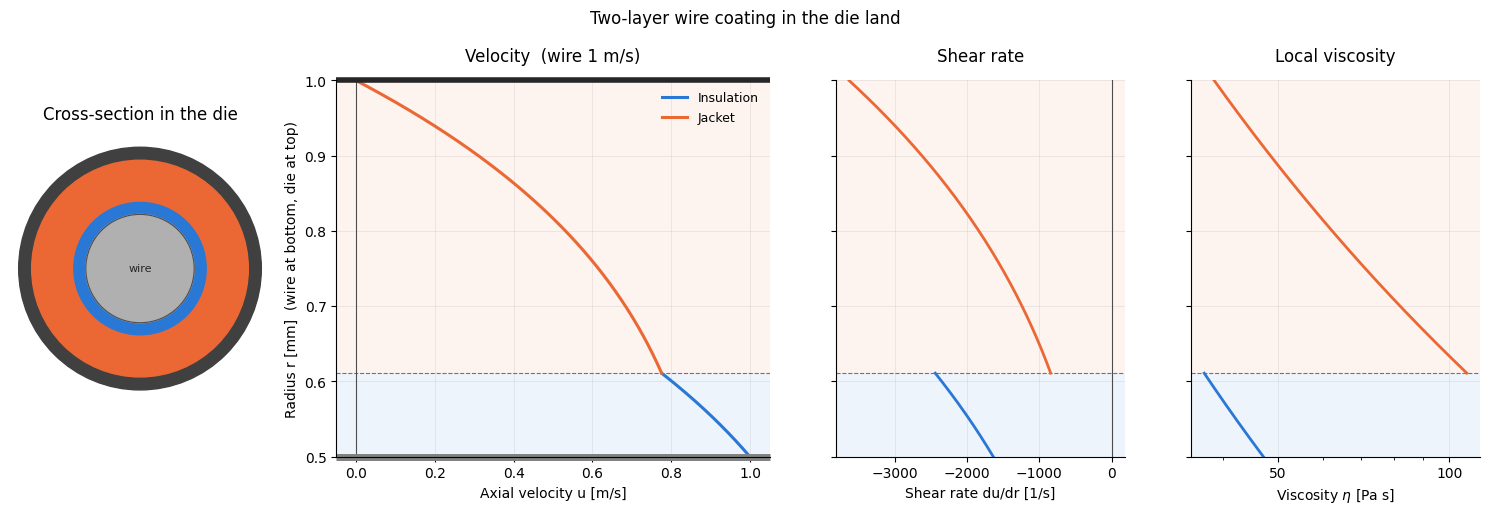

In [3]:
Rw, Rd = 0.50e-3, 1.00e-3          # wire and die-land radius [m]
Vw     = 1.0                       # line speed [m/s]
L      = 5e-3                      # land length [m]
names  = ["Insulation", "Jacket"]
K      = [4000.0, 12000.0]         # Pa s^n
n      = [0.40,   0.30]
t_final = [0.10e-3, 0.20e-3]       # final coating thicknesses [m]

Q = flow_rates_from_coating(Rw, t_final, Vw)
sol1 = solve_annular(Q, K, n, Rw, Rd, V_wire=Vw)
report(sol1, names, L=L)
plot_profiles(sol1, names, title="Two-layer wire coating in the die land");

### Example 2: line-speed sweep at fixed final coating

The final thicknesses from Example 1 are held fixed, so both flow rates scale with the line speed. For a single power-law fluid, every stress would then scale as $V_w^{\,n}$ and the profile shape would not change at all. With **two different $n$** that is no longer exact:
* The **wire force** follows the inner layer's index ($\propto V_w^{\,n_1}$, about $V^{0.40}$), because only the inner layer touches the wire.
* The **pressure gradient** need not follow either $n$. It is the net of the drag flow and the pressure flow the die must supply, and here it scales roughly as $V^{0.25}$, below both indices. With equal indices it would be exactly $V^{\,n}$.
* The **interface radius** in the die drifts, but for this pair only by a few micrometres over two decades of speed. The in-die layer split is set mainly by the coating split, not by the line speed.

In [ ]:
speeds = np.geomspace(0.1, 10, 21)
res = [solve_annular(flow_rates_from_coating(Rw, t_final, V), K, n, Rw, Rd, V_wire=V) for V in speeds]
G_v  = np.array([s["G"] for s in res])
ri_v = np.array([s["radii"][1] for s in res])
F_v  = np.array([-2*np.pi*Rw*s["tau_wire"]*L for s in res])

fig, axs = plt.subplots(1, 3, figsize=(14, 4))
axs[0].plot(speeds, G_v*1e-6, color=LAYER_COLORS[0], lw=2); axs[0].set_xscale("log")
axs[0].axhline(0, color="0.3", lw=0.8)
axs[0].set_ylabel("-dp/dz [MPa/m]"); axs[0].set_title("Pressure gradient in the land")
axs[1].plot(speeds, ri_v*1e3, color=LAYER_COLORS[1], lw=2); axs[1].set_xscale("log")
axs[1].set_ylabel("Interface radius in die [mm]"); axs[1].set_title("Interface position")
axs[2].loglog(speeds, F_v, color=LAYER_COLORS[2], lw=2)
for axis in (axs[2].yaxis,):
    axis.set_major_locator(matplotlib.ticker.LogLocator(base=10, subs=(1, 2, 5)))
    axis.set_major_formatter(matplotlib.ticker.FuncFormatter(lambda v, _: f"{v:g}"))
    axis.set_minor_formatter(matplotlib.ticker.NullFormatter())
axs[2].set_ylabel(f"Wire pull force over L = {L*1e3:.0f} mm [N]"); axs[2].set_title("Drag force on the wire")
for ax in axs:
    ax.set_xlabel("Line speed [m/s]"); _style(ax)
fig.tight_layout(); plt.show()
kF = np.polyfit(np.log(speeds), np.log(F_v), 1)[0]
kG = np.polyfit(np.log(speeds), np.log(np.abs(G_v)), 1)[0]
print(f"interface radius moves from {ri_v[0]*1e3:.4f} mm to {ri_v[-1]*1e3:.4f} mm over 0.1-10 m/s;"
      f" -dp/dz ~ V^{kG:.2f}, wire force ~ V^{kF:.2f}  (n = {n[0]} and {n[1]})")

### Example 3: coating-thickness sweep and the sign of the pressure gradient

The line speed is fixed at 1 m/s and the inner-to-outer thickness ratio at 1:2, while the total coating thickness is varied. The pressure gradient changes sign at the thickness the wire drags through the land **by itself**:
* **Thinner coatings** need the pressure to rise toward the exit ($-dp/dz < 0$). The wire pulls out more melt than is delivered, and the die must hold it back. Much of the jacket near the die wall is then almost stagnant, because the strongly shear-thinning jacket concentrates its shear near the wire. Only for the very thinnest coatings does the melt next to the die wall actually flow backward.
* **Thicker coatings** need positive die pressure, which pushes melt out faster than drag alone.

The curve bends where the zero-stress radius passes through the die wall, the annular counterpart of the bend in the slit notebook's wall-speed sweep.

In [ ]:
t_tot = np.linspace(0.04e-3, 0.48e-3, 23)
sw = [solve_annular(flow_rates_from_coating(Rw, [t/3, 2*t/3], Vw), K, n, Rw, Rd, V_wire=Vw) for t in t_tot]
G_t = np.array([s["G"] for s in sw])
umin_t = np.array([min(p["u"].min() for p in profiles(s, 60)) for s in sw])
i0 = np.where(np.diff(np.sign(G_t)))[0][0]
t0 = t_tot[i0] - G_t[i0]*(t_tot[i0+1] - t_tot[i0])/(G_t[i0+1] - G_t[i0])
print(f"drag-only total coating thickness (dp/dz = 0) ~ {t0*1e3:.3f} mm at {Vw} m/s")

fig, axs = plt.subplots(1, 2, figsize=(12, 4))
axs[0].plot(t_tot*1e3, G_t*1e-6, color=LAYER_COLORS[0], lw=2)
axs[0].axhline(0, color="0.3", lw=0.8); axs[0].axvline(t0*1e3, color="0.5", lw=0.8, ls="--")
axs[0].set_ylabel("-dp/dz [MPa/m]"); axs[0].set_title("Pressure gradient vs final coating thickness")
axs[1].plot(t_tot*1e3, np.minimum(umin_t, 0), color=LAYER_COLORS[1], lw=2)
axs[1].axhline(0, color="0.3", lw=0.8)
axs[1].set_ylabel("Most negative velocity [m/s]"); axs[1].set_title("Backflow appears only for very thin coatings")
for ax in axs:
    ax.set_xlabel("Total final coating thickness [mm]"); _style(ax)
fig.tight_layout(); plt.show()

thin = sw[0]
report(thin, names, L=L)
plot_profiles(thin, names, title=f"Thin coating ({t_tot[0]*1e3:.2f} mm total): pressure build-up and backflow");

## 5. Calculation: enter your own case

Edit the inputs and run the cell. List layers **from the wire outward** (1 to 5 layers; two for a standard insulation and jacket).

* `R_wire`, `R_die`: wire radius and die-land radius [m]
* `V_wire`: line speed [m/s]. `V_die` is normally 0.
* `K`, `n`: power-law consistency [Pa·sⁿ] and index for each layer. For a Newtonian layer, `K` is the viscosity and `n` = 1.
* Either set `use_thickness = True` and give the **final coating thicknesses** `t_final` [m], or set it to `False` and give the flow rates `Q` [m³/s] directly.
* `L`: die land length [m], used only for the pressure-drop and wire-force estimates.

A negative `-dp/dz` means the pressure **rises** toward the die exit: the wire drags more melt than you are delivering.

In [ ]:
# ---------------- INPUTS ----------------
R_wire = 0.40e-3          # wire radius [m]
R_die  = 0.85e-3          # die-land radius [m]
V_wire = 2.0              # line speed [m/s]
V_die  = 0.0              # die wall speed [m/s] (normally 0)
L      = 4e-3             # land length [m]

names = ["Inner", "Outer"]        # wire outward
K     = [3000.0, 9000.0]          # consistency [Pa s^n]
n     = [0.45,   0.32]            # power-law index [-]

use_thickness = True
t_final = [0.08e-3, 0.22e-3]      # final coating thicknesses [m]  (if use_thickness)
Q       = [3.0e-7, 1.2e-6]        # flow rates [m^3/s]             (if not use_thickness)
# ----------------------------------------

if use_thickness:
    Q = flow_rates_from_coating(R_wire, t_final, V_wire)
sol = solve_annular(Q, K, n, R_wire, R_die, V_wire=V_wire, V_die=V_die)
report(sol, names, L=L)
plot_profiles(sol, names);